# Question 1
> Note: I originally did this in a python file, which is why the definitions are at the top of the file so I could keep track of them

Included parts (please verify)
- Read the web log file line by line
- Parsing each log entry to extract the relevant attributes from the raw log data
- Converting the parsed log entries into Pandas DataFrame
- Displaying the resulting DataFrame in a table format similar to the example provided in task specification

In [6]:
import re

import pandas as pd
import seaborn as sns

LINE_RE = re.compile(
    r'^(\S+) (\S+) (\S+) \[([^\]]+)\] "([^"]*)" (\S+) (\S+) "([^"]*)" "([^"]*)" "([^"]*)"$'
)
COLUMNS = [
    "ip",
    "ident",
    "auth",
    "time",
    "method",
    "path",
    "proto",
    "status",
    "size",
    "referrer",
    "user_agent",
]
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".gif", ".ico", ".webp", ".svg", ".bmp"}
AUDIO_EXTENSIONS = {".mp3", ".wav", ".ogg", ".oga", ".aac", ".m4a", ".flac", ".wma"}
IMAGE_SEGMENTS = {"image", "images", "productimage"}
AUDIO_SEGMENTS = {"audio", "sound", "mp3"}
CONTENT_TYPES = {
    "product",
    "filter",
    "browse",
    "blog",
    "search",
    "basket",
    "login",
    "customer",
    "article",
    "comparison",
    "order",
}
BOT_RE = re.compile(
    r"bot|spider|crawler|slurp|ahrefs|semrush|dotbot|petalbot|yandex|baidu|sogou|duckduck",
    re.IGNORECASE,
)
SESSION_GAP = pd.Timedelta(minutes=30)
MIN_SUPPORT = 0.02
MIN_CONFIDENCE = 0.1

def parse_log(path):
    """Parse combined log lines into the 11 task columns. '-' stays literal."""
    rows = []
    failed = []
    with open(path, "r", encoding="utf-8") as f:
        for line_no, raw_line in enumerate(f, start=1):
            line = raw_line.rstrip("\r\n")
            match = LINE_RE.match(line)
            if match is None:
                failed.append(line_no)
                continue
            ip, ident, auth, time, request, status, size, referrer, user_agent, _trailing = match.groups()
            parts = request.split(" ")
            if len(parts) >= 3 and parts[-1].startswith("HTTP"):
                method, proto = parts[0], parts[-1]
                url_path = " ".join(parts[1:-1])
            else:
                method, proto = parts[0], ""
                url_path = " ".join(parts[1:])
            rows.append(
                (ip, ident, auth, time, method, url_path, proto, status, size, referrer, user_agent)
            )
    frame = pd.DataFrame(rows, columns=COLUMNS)
    return frame, failed


def path_bits(url_path):
    raw = url_path.split("?", 1)[0]
    return [bit for bit in raw.split("/") if bit]


def media_kind(url_path):
    """Classify image and audio from the path segments that occur in this log.

    Product photos are served from `/image/...` and `/static/images/...` with
    no file extension. `/m/productimage` and `/site/productimage` are image
    endpoints, and `/settings/logo` is the shop logo. A category slug such as
    `audio-and-video-equipment` is a document, not an audio file, because the
    segment is not exactly `audio`.
    """
    bits = [bit.lower() for bit in path_bits(url_path)]
    last = bits[-1] if bits else ""
    extension = "." + last.rsplit(".", 1)[-1] if "." in last else ""
    if any(bit in IMAGE_SEGMENTS for bit in bits):
        return "image"
    if len(bits) >= 2 and bits[0] == "settings" and bits[1] == "logo":
        return "image"
    if extension in IMAGE_EXTENSIONS or last.startswith("apple-touch-icon") or last == "favicon.ico":
        return "image"
    if any(bit in AUDIO_SEGMENTS for bit in bits) or extension in AUDIO_EXTENSIONS:
        return "audio"
    return ""


def page_family(url_path):
    """Collapse a content URL to a page family. Assets and ajax calls return None."""
    bits = path_bits(url_path)
    if not bits or bits[0].lower() in {"index", "index.php"}:
        return "home"
    top = bits[0]
    if top == "m":
        if len(bits) == 1:
            return "m/home"
        second = bits[1]
        if second in CONTENT_TYPES:
            return "m/" + second
        return None
    if top in CONTENT_TYPES:
        return top
    return None


logs, failed_lines = parse_log("CAB330_asm2_datasets 2/Dataset4Task4_26.txt")
print(f"Lines read: {len(logs) + len(failed_lines)}")
print(f"Rows parsed: {len(logs)}")
print(f"Lines that did not match the combined-log pattern: {len(failed_lines)}")
logs.info()

Lines read: 15000
Rows parsed: 15000
Lines that did not match the combined-log pattern: 0
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   ip          15000 non-null  str  
 1   ident       15000 non-null  str  
 2   auth        15000 non-null  str  
 3   time        15000 non-null  str  
 4   method      15000 non-null  str  
 5   path        15000 non-null  str  
 6   proto       15000 non-null  str  
 7   status      15000 non-null  str  
 8   size        15000 non-null  str  
 9   referrer    15000 non-null  str  
 10  user_agent  15000 non-null  str  
dtypes: str(11)
memory usage: 1.3 MB


# Question 2

Included parts (please verify):
- Convert the text-based `time` column into a proper Pandas `datetime` object
- Remove the original attributes that contain a large proportion of missing values or are no longer required for the analysis
- Sort the remaining records in descending order based on the `datetime` column and then display the first 10 rows of the sorted DataFrame

In [7]:
logs["Datetime"] = pd.to_datetime(logs["time"], format="%d/%b/%Y:%H:%M:%S %z")
if logs["Datetime"].isna().any():
    raise ValueError("One or more timestamps could not be parsed.")

logs = logs.replace("-", pd.NA)
print("Missing values after replacing '-' :")
print(logs.isna().sum().to_string())

cleaned = logs.drop(columns=["ident", "auth", "referrer", "size", "time"]).copy()
cleaned["status"] = cleaned["status"].astype(int)
cleaned = cleaned.sort_values("Datetime", ascending=False, kind="mergesort")
cleaned = cleaned[
    ["ip", "method", "path", "proto", "status", "Datetime", "user_agent"]
].reset_index(drop=True)

print()
print(f"Rows after cleaning: {len(cleaned)}")
print(f"Distinct ip values: {cleaned['ip'].nunique()}")
print(f"Earliest request: {cleaned['Datetime'].min()}")
print(f"Latest request: {cleaned['Datetime'].max()}")
print()
preview = cleaned.head(10).copy()
preview["path"] = preview["path"].str.slice(0, 60)
preview["user_agent"] = preview["user_agent"].str.slice(0, 48)
print(preview.to_string(index=True))

Missing values after replacing '-' :
ip                0
ident         15000
auth          15000
time              0
method            0
path              0
proto             0
status            0
size              0
referrer       8234
user_agent      109
Datetime          0

Rows after cleaning: 15000
Distinct ip values: 784
Earliest request: 2019-01-22 03:56:14+03:30
Latest request: 2019-01-22 04:56:13+03:30

                ip method                                                          path     proto  status                  Datetime                                        user_agent
0      91.99.72.15    GET                                    /product/31055?model=60906  HTTP/1.1     200 2019-01-22 04:56:13+03:30  Mozilla/5.0 (Windows NT 6.2; Win64; x64; rv:16.0
1    207.46.13.136    GET                                  /filter?f=b2%2Cb484%2Cp1&o=b  HTTP/1.1     302 2019-01-22 04:56:13+03:30  Mozilla/5.0 (compatible; bingbot/2.0; +http://ww
2  146.185.133.111    GET             

# Question 3

Included parts (please verify):
- Remove all requests for image and audio files from a web-server log dataset
- Determine and report the number of rows (objects) containing requests for images, and the number of rows (objects) containing requests for audio

In [11]:
cleaned["media"] = cleaned["path"].map(media_kind)
media_counts = cleaned["media"].value_counts()
n_image = int(media_counts.get("image", 0))
n_audio = int(media_counts.get("audio", 0))
print(f"Image requests: {n_image}")
print(f"Audio requests: {n_audio}")

def image_reason(url_path):
    bits = [bit.lower() for bit in path_bits(url_path)]
    last = bits[-1] if bits else ""
    extension = "." + last.rsplit(".", 1)[-1] if "." in last else ""
    if any(bit in IMAGE_SEGMENTS for bit in bits):
        return "path segment image / images / productimage"
    if len(bits) >= 2 and bits[0] == "settings" and bits[1] == "logo":
        return "/settings/logo"
    if extension in IMAGE_EXTENSIONS or last.startswith("apple-touch-icon") or last == "favicon.ico":
        return "image extension or icon file"
    return ""

image_rows = cleaned.loc[cleaned["media"] == "image"]
print()
print(image_rows["path"].map(image_reason).value_counts().to_string())
print()
print("Audio path examples:")
print(cleaned.loc[cleaned["media"] == "audio", "path"].head(10).to_string())

pages = cleaned.loc[cleaned["media"] == ""].drop(columns=["media"]).copy()
print()
print(f"Page and other non-media rows kept: {len(pages)}")

Image requests: 6780
Audio requests: 0

path
path segment image / images / productimage    6203
/settings/logo                                 384
image extension or icon file                   193

Audio path examples:
Series([], )

Page and other non-media rows kept: 8220


# Question 4

Included parts (please verify):
- Define and identify user sessions in the web log data. A *user session* is a sequence of web requests made by the same user during a defined period of activity on a website, such as a 30-minute session timeout
    - Provide a clean definition of a user session to be used for Task 4, including the criteria used to determine when a new session begins
    - Develop code to identify user sessions in the web log data and add the following columns to the dataset:
        - `SessionID` (a unique identifier assigned to each user session)
        - `Steps` (the sequential number of each web request within a session, representing the user's navigation steps during that session)
    - Use the sample output provided in the task specification as a reference for the expected result

Sessions: 602
Rows in the session table: 8220
Session length (requests):
count     602.000000
mean       13.654485
std       102.987586
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max      2018.000000
Sessions with at least two requests: 328

                 ip method                                                     path     proto  status                  Datetime  SessionID  Steps
0      54.36.149.41    GET  /filter/27|13%20%D9%85%DA%AF%D8%A7%D9%BE%DB%8C%DA%A9%D8  HTTP/1.1     200 2019-01-22 03:56:14+03:30          1      1
3       91.99.72.15    GET  /product/31893/62100/%D8%B3%D8%B4%D9%88%D8%A7%D8%B1-%D8  HTTP/1.1     200 2019-01-22 03:56:17+03:30          2      1
401   207.46.13.136    GET                                           /product/10214  HTTP/1.1     200 2019-01-22 03:56:18+03:30          3      1
950   66.249.66.194    GET  /filter/b41,b665,c150%7C%D8%A8%D8%AE%D8%A7%D8%B1%D9%BE%  HTTP/1.1     200 2019-01-22 03:56:18+03:30      

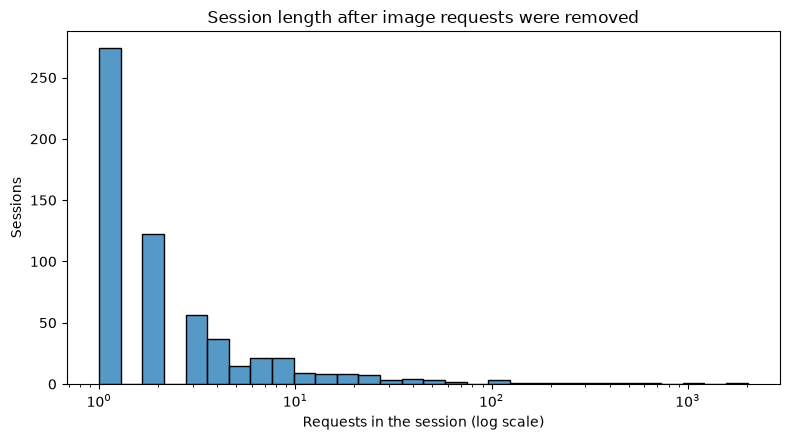

In [16]:
import matplotlib.pyplot as plt
pages = pages.sort_values(["Datetime", "ip", "path"], kind="mergesort").reset_index(drop=True)
gap = pages.groupby("ip", sort=False)["Datetime"].diff()
pages["new_session"] = gap.isna() | (gap > SESSION_GAP)
pages["ip_session"] = pages.groupby("ip", sort=False)["new_session"].cumsum()

session_starts = (
    pages.loc[pages["new_session"], ["ip", "ip_session", "Datetime"]]
    .sort_values(["Datetime", "ip"], kind="mergesort")
    .reset_index(drop=True)
)

session_starts["SessionID"] = session_starts.index + 1
pages = pages.merge(
    session_starts[["ip", "ip_session", "SessionID"]],
    on=["ip", "ip_session"],
    how="left"
)
pages = pages.sort_values(["SessionID", "Datetime", "path"], kind="mergesort")
pages["Steps"] = pages.groupby("SessionID", sort=False).cumcount() + 1
pages = pages.drop(columns=["new_session", "ip_session"]).reset_index(drop=True)

session_lengths = pages.groupby("SessionID").size()
print(f"Sessions: {pages['SessionID'].nunique()}")
print(f"Rows in the session table: {len(pages)}")
print("Session length (requests):")
print(session_lengths.describe().to_string())
print(f"Sessions with at least two requests: {int((session_lengths >=2).sum())}")
print()
session_view = pages.sort_values(["Datetime", "SessionID", "Steps"], kind="mergesort")
session_preview = session_view[
    ["ip", "method", "path", "proto", "status", "Datetime", "SessionID", "Steps"]
].head(15).copy()
session_preview["path"] = session_preview["path"].str.slice(0, 55)
print(session_preview.to_string(index=True))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(session_lengths, bins=30, log_scale=(True, False), ax=ax)
ax.set_title("Session length after image requests were removed")
ax.set_xlabel("Requests in the session (log scale)")
ax.set_ylabel("Sessions")
fig.tight_layout()
plt.show()

# Question 5

Included parts (please verify):
- Select an appropriate unsupervised learning method and justify the rationale for your choice
- Identify and explain the variables/features included in the analysis and justify their selection
- Present a case study demonstrating how the discovered patterns or clusters can be used to support data-drive decision making

Association mining is the method used here. A session is already a basket of pages. The shop needs to know which page types occur together so that it can improve the websites navigation. Apriori states those co-occurences as support, confidence, and lift. Clustering on the otherhand, would group similar sessions, but it would not say "visitors who open these two page types also open a third".

- Apriori is useful for finding relationships, and frequent term combinations.
- Clustering is useful for grouping pages by topic or similarity

In [ ]:
pages["family"] = pages["path"].map(page_family)
pages["is_crawler"] = pages["user_agent"].str.contains(BOT_RE, na=False)
print(f"Non-media rows from a crawler user agent: {int(pages['is_crawler'].sum())} of {len(pages)}")
print("Page families kept as items:")
print(pages["family"].value_counts(dropna=False).to_string())

def session_baskets(frame):
    grouped = frame.groupby("SessionID", sort=True)["family"].apply(
        lambda values: sorted({value for value in values if pd.notna(value)})
    )
    return [basket for basket in grouped if basket]